In [160]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, silhouette_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree

import nltk
from nltk.corpus import stopwords
from textblob import TextBlob
from wordcloud import WordCloud

# one seed for everything so reruns give identical results. the number doesnt matter aslong as it is known and consistant
# the meaning of life the universe and everything
RANDOM_STATE = 42

# same look for every chart
sns.set_style("whitegrid")

# Folder where charts get saved (handy for the report and slides later)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    """Save the current figure into the figures folder (call before plt.show())."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [161]:
# Load the raw file (keep it in the same folder as this notebook)
DATA_FILE = "turtle_reviews.csv"
reviews_raw = pd.read_csv(DATA_FILE)

# Quick look: size and first rows
print("Rows, columns:", reviews_raw.shape)
reviews_raw.head()

Rows, columns: (2000, 11)


,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [162]:
# data types and non-null counts
reviews_raw.info()

# check for missing values
print("\nMissing values per column:")
print(reviews_raw.isna().sum())

# check for dulication 
print("\nDuplicate rows:", reviews_raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   language                2000 non-null   object 
 7   platform                2000 non-null   object 
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   object 
 10  summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 172.0+ KB

Missing values per column:
gender                    0
age                       0
remuneration (k£)         0
spending_score (1-100)    0


In [163]:
# language and platform should be the same value on every row, so they tell us nothing
#Printing the unique counts to prove it before we drop them.
print(reviews_raw[["language", "platform"]].nunique())

language    1
platform    1
dtype: int64


In [164]:
# Work on a copy so the raw data stays untouched.
# Drop the two single value columns and give the weird names (spaces, brackets, the pound sign) better/simpler ones.
reviews = (
    reviews_raw
    .drop(columns=["language", "platform"])
    .rename(columns={
        "remuneration (k£)": "remuneration",
        "spending_score (1-100)": "spending_score",
    })
)

# Only drop rows that are identical across EVERY column. 
#Repeated review text on its own is fine as lots of people write "five stars"
n_before = len(reviews)
reviews = reviews.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(reviews)} fully duplicated rows, {len(reviews)} remain.")

# Check the categories look consistent (no 'Male' vs 'male' type problems)
print("\n", reviews["gender"].value_counts())
print("\n", reviews["education"].value_counts())

Dropped 0 fully duplicated rows, 2000 remain.

 gender
Female    1120
Male       880
Name: count, dtype: int64

 education
graduate        900
PhD             460
postgraduate    400
diploma         190
Basic            50
Name: count, dtype: int64


In [165]:
# save the cleaned data. Different file name from the R script's output, so the two scripts dont overwrite
# Also save cleaned versious 
reviews["review_clean"] = (
    reviews["review"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-z\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

reviews["summary_clean"] = (
    reviews["summary"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-z\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Save the cleaned data
CLEAN_FILE = "turtle_reviews_clean_py.csv"
reviews.to_csv(CLEAN_FILE, index=False)

# Sense-check: reload the saved file and verify it matches
reviews_check = pd.read_csv(CLEAN_FILE)

assert reviews_check.shape == reviews.shape, "Saved file doesn't match!"

print("Clean file saved and verified:", reviews_check.shape)
print("\nSaved columns:")
print(reviews_check.columns.tolist())

# Show the original and cleaned text side-by-side
reviews_check[["review", "review_clean", "summary", "summary_clean"]].head()

Clean file saved and verified: (2000, 11)

Saved columns:
['gender', 'age', 'remuneration', 'spending_score', 'loyalty_points', 'education', 'product', 'review', 'summary', 'review_clean', 'summary_clean']


,review,review_clean,summary,summary_clean
0,"When it comes to a DM's screen, the space on t...",when it comes to a dms screen the space on the...,The fact that 50% of this space is wasted on a...,the fact that of this space is wasted on art a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,an open letter to galeforce your unpainted min...,Another worthless Dungeon Master's screen from...,another worthless dungeon masters screen from ...
2,"Nice art, nice printing. Why two panels are f...",nice art nice printing why two panels are fill...,"pretty, but also pretty useless",pretty but also pretty useless
3,Amazing buy! Bought it as a gift for our new d...,amazing buy bought it as a gift for our new dm...,Five Stars,five stars
4,As my review of GF9's previous screens these w...,as my review of gfs previous screens these wer...,Money trap,money trap


In [166]:
NUMERIC_COLS = ["age", "remuneration", "spending_score", "loyalty_points"]

# summary: mean, spread, quartiles, min and max
reviews[NUMERIC_COLS].describe().round(2)

,age,remuneration,spending_score,loyalty_points
count,2000.00,2000.00,2000.00,2000.00
mean,39.49,48.08,50.00,1578.03
std,13.57,23.12,26.09,1283.24
min,17.00,12.30,1.00,25.00
25%,29.00,30.34,32.00,772.00
50%,38.00,47.15,50.00,1276.00
75%,49.00,63.96,73.00,1751.25
max,72.00,112.34,99.00,6847.00


In [167]:
# Shape of each numeric variable - skewness, excess kurtosis, Shapiro-Wilk
shape_rows = []
for col in NUMERIC_COLS:
    shapiro_stat, shapiro_p = stats.shapiro(reviews[col])
    shape_rows.append({
        "variable": col,
        "skewness": stats.skew(reviews[col]),
        "excess_kurtosis": stats.kurtosis(reviews[col]),  # 0 = normal
        "shapiro_p_value": shapiro_p,
    })
shape_table = pd.DataFrame(shape_rows).set_index("variable").round(3)
print(shape_table)


def describe_skew(value):
    """Turn a skewness number into plain English."""
    if abs(value) < 0.5:
        return "roughly symmetric"
    direction = "right (long tail of high values)" if value > 0 else "left (long tail of low values)"
    strength = "moderately" if abs(value) < 1 else "strongly"
    return f"{strength} skewed to the {direction}"


# spell out the verdict for the target variable
skew_lp = shape_table.loc["loyalty_points", "skewness"]
kurt_lp = shape_table.loc["loyalty_points", "excess_kurtosis"]
print(f"\nLoyalty points are {describe_skew(skew_lp)}.")
print(f"Excess kurtosis of {kurt_lp:.2f} means tails that are "
      f"{'heavier' if kurt_lp > 0 else 'lighter'} than a normal distribution.")

                skewness  excess_kurtosis  shapiro_p_value
variable                                                  
age                0.609           -0.191              0.0
remuneration       0.413           -0.408              0.0
spending_score    -0.042           -0.890              0.0
loyalty_points     1.464            1.709              0.0

Loyalty points are strongly skewed to the right (long tail of high values).
Excess kurtosis of 1.71 means tails that are heavier than a normal distribution.


Saved to: C:\Users\Tomat\anaconda_projects\cff9c5e8-4df1-4d8e-bce1-2c7a31d45416\figures\figure1_loyalty_distribution.png


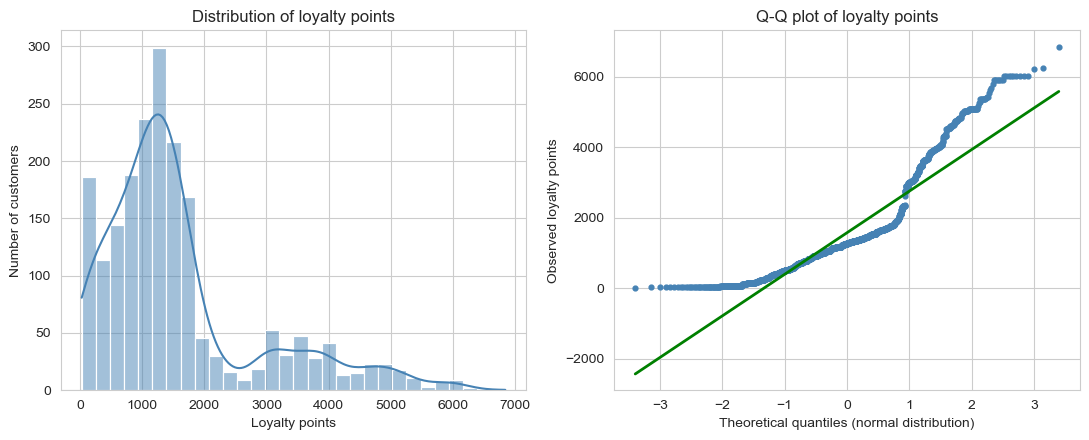

In [168]:
# histogram  and Q-Q plot of loyalty points
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# left panel: histogram with a smooth curve over the top
sns.histplot(reviews["loyalty_points"], bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of loyalty points")
axes[0].set_xlabel("Loyalty points")
axes[0].set_ylabel("Number of customers")

# Right panel: Q-Q plot, drawn by hand so we control the colours.
# probplot hands back the dots (osm, osr) and the reference line (slope, intercept).
(osm, osr), (slope, intercept, r) = stats.probplot(reviews["loyalty_points"], dist="norm")
axes[1].scatter(osm, osr, color="steelblue", s=12)                        # the data
axes[1].plot(osm, slope * osm + intercept, color="green", linewidth=2)    # "perfectly normal" line
axes[1].set_title("Q-Q plot of loyalty points")
axes[1].set_xlabel("Theoretical quantiles (normal distribution)")
axes[1].set_ylabel("Observed loyalty points")

plt.tight_layout()

# Save at higher resolution for the report
#  full path - easy to find
fig_path = FIG_DIR / "figure1_loyalty_distribution.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
print("Saved to:", fig_path.resolve())
plt.show()

                lower_fence  upper_fence  outliers  pct_of_customers
variable                                                            
age                    -1.0         79.0         0               0.0
remuneration          -20.1        114.4         0               0.0
spending_score        -29.5        134.5         0               0.0
loyalty_points       -696.9       3220.1       266              13.3


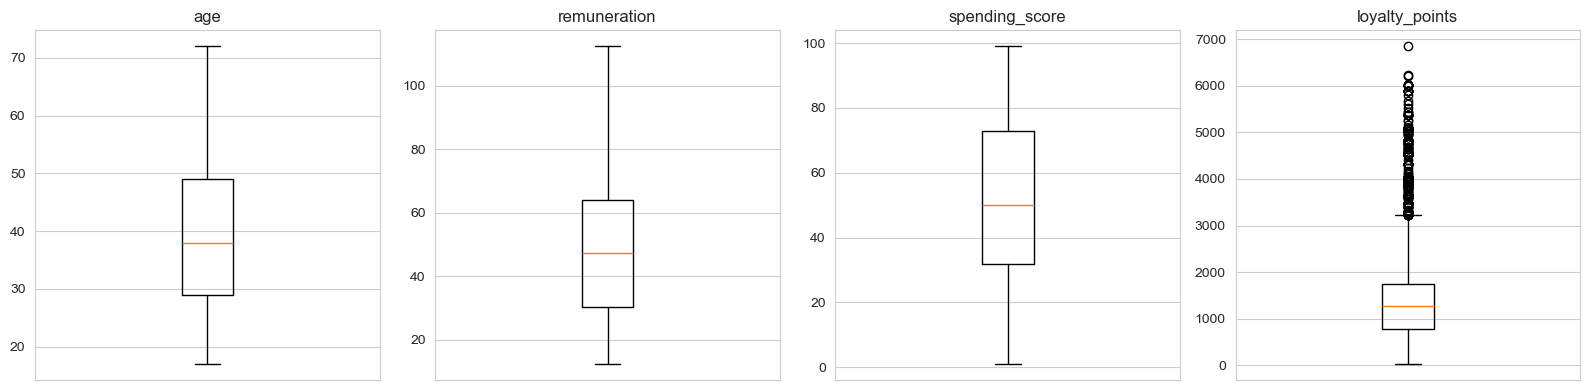

In [169]:
# Ootliers using the standard 1.5 x IQR rule 
# how many points lie outside the whiskers
outlier_rows = []
for col in NUMERIC_COLS:
    q1, q3 = reviews[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((reviews[col] < low) | (reviews[col] > high)).sum())
    outlier_rows.append({"variable": col, "lower_fence": round(low, 1),
                         "upper_fence": round(high, 1), "outliers": n_out,
                         "pct_of_customers": round(100 * n_out / len(reviews), 1)})
print(pd.DataFrame(outlier_rows).set_index("variable"))

# Boxplots to see them (dots beyond the whiskers are the flagged outliers)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, NUMERIC_COLS):
    ax.boxplot(reviews[col])
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
save_fig("02_boxplots")
plt.show()

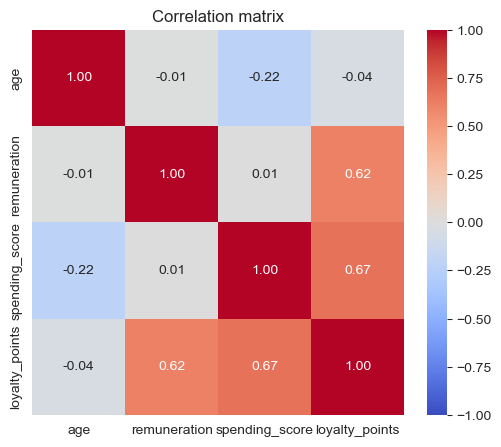

In [170]:
# How do the numeric variables relate to each other
corr = reviews[NUMERIC_COLS].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
save_fig("02_correlation_heatmap")
plt.show()

In [171]:
FEATURES = ["age", "remuneration", "spending_score"]
TARGET = "loyalty_points"

X = reviews[FEATURES]
y = reviews[TARGET]

# 70% to learn from, 30% held back for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

# We'll collect every model's scores in here and compare them in Section 5
model_results = []


def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    """Score a fitted model on train and test data and return the results as a dict."""
    test_pred = model.predict(X_te)
    return {
        "model": name,
        "train_R2": r2_score(y_tr, model.predict(X_tr)),
        "test_R2": r2_score(y_te, test_pred),
        "test_RMSE": np.sqrt(mean_squared_error(y_te, test_pred)),
        "test_MAE": mean_absolute_error(y_te, test_pred),
    }

Train rows: 1400 | Test rows: 600


In [172]:
# fit the baseline linear model on the training data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# what the model learned --- baseline plus a points-per-unit "price" for each feature
print(f"Intercept: {linear_model.intercept_:.1f}")
for feature, coef in zip(FEATURES, linear_model.coef_):
    print(f"  {feature}: {coef:+.2f} loyalty points per unit")

# Standardised coefficients (each coefficient scaled by feature spread vs target spread) 
#this means features measured in different units can be compared fairly
std_coefs = pd.Series(linear_model.coef_ * X_train.std() / y_train.std(), index=FEATURES)
print("\nStandardised coefficients (bigger absolute value = stronger driver):")
print(std_coefs.round(3).sort_values(key=abs, ascending=False))

# Score it on both train and test
linear_scores = evaluate_model("Linear regression", linear_model,
                               X_train, X_test, y_train, y_test)
model_results.append(linear_scores)
print("\n", {k: (round(v, 3) if not isinstance(v, str) else v) for k, v in linear_scores.items()})

Intercept: -2185.5
  age: +10.77 loyalty points per unit
  remuneration: +34.48 loyalty points per unit
  spending_score: +33.72 loyalty points per unit

Standardised coefficients (bigger absolute value = stronger driver):
spending_score    0.682
remuneration      0.617
age               0.114
dtype: float64

 {'model': 'Linear regression', 'train_R2': 0.844, 'test_R2': 0.83, 'test_RMSE': np.float64(524.67), 'test_MAE': 398.027}


VIF per feature:
age               1.06
remuneration      1.00
spending_score    1.06
dtype: float64

Negative predictions on test set: 54 of 600


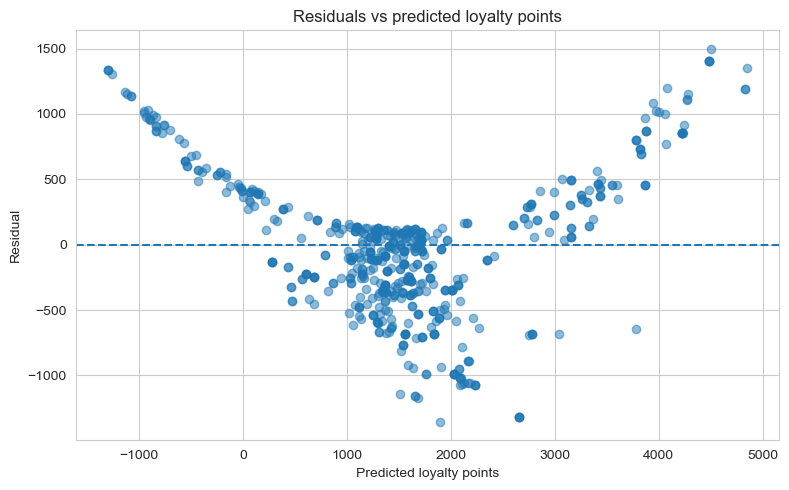

In [173]:
# sanity checks on the linear models assumptions.

# 1. Multicollinearity if VIF above 5 something is wrong. should be close to 1
def calculate_vif(df):
    """Variance inflation factor per column: how well the others predict it."""
    vifs = {}
    for col in df.columns:
        others = df.drop(columns=col)
        r2 = LinearRegression().fit(others, df[col]).score(others, df[col])
        vifs[col] = 1 / (1 - r2)
    return pd.Series(vifs).round(2)

print("VIF per feature:")
print(calculate_vif(X_train))

# 2. predictions below zero make no sense for loyalty points
test_pred = linear_model.predict(X_test)
print(f"\nNegative predictions on test set: {(test_pred < 0).sum()} of {len(test_pred)}")

# 3. residuals should be centred on 0 with no pattern
residuals = y_test - test_pred

# graph residual vs predicted
plt.figure(figsize=(8, 5))
plt.scatter(test_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")

plt.title("Residuals vs predicted loyalty points")
plt.xlabel("Predicted loyalty points")
plt.ylabel("Residual")

plt.tight_layout()
save_fig("08_residuals_vs_predicted")
plt.show()

In [174]:
# Improvement
# let the model capture an INTERACTION
#the effect of spending score might depend on how much someone earns (and vice versa).
def add_interaction(df):
    """Return a copy of df with an extra remuneration x spending_score column."""
    out = df.copy()
    out["remuneration_x_spending"] = out["remuneration"] * out["spending_score"]
    return out

X_train_int = add_interaction(X_train)
X_test_int = add_interaction(X_test)

interaction_model = LinearRegression().fit(X_train_int, y_train)
interaction_scores = evaluate_model("Linear regression + interaction", interaction_model,
                                    X_train_int, X_test_int, y_train, y_test)
model_results.append(interaction_scores)

# Did it help? Compare held-out (test) performance.
print(f"Baseline test R2:    {linear_scores['test_R2']:.3f}  (RMSE {linear_scores['test_RMSE']:.1f})")
print(f"Interaction test R2: {interaction_scores['test_R2']:.3f}  (RMSE {interaction_scores['test_RMSE']:.1f})")

Baseline test R2:    0.830  (RMSE 524.7)
Interaction test R2: 0.983  (RMSE 166.4)


In [175]:
# turn gender (sex) and education into 0/1 columns so the tree can use them
tree_features = ["age", "remuneration", "spending_score", "gender", "education"]
X_tree = pd.get_dummies(reviews[tree_features], drop_first=True, dtype=int)

# Same seed and test size as before = exactly the same customers in train and test
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_tree, y, test_size=0.3, random_state=RANDOM_STATE
)
print("Tree features:", list(X_tree.columns))

Tree features: ['age', 'remuneration', 'spending_score', 'gender_Male', 'education_PhD', 'education_diploma', 'education_graduate', 'education_postgraduate']


In [176]:
# Step 1: grow a full unpruned tree to see what overfitting looks like
# Near perfect training score + weaker test score = memorising / not learning.
full_tree = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train_t, y_train_t)
full_scores = evaluate_model("Decision tree (unpruned)", full_tree,
                             X_train_t, X_test_t, y_train_t, y_test_t)
print(f"Unpruned tree | depth {full_tree.get_depth()}, {full_tree.get_n_leaves()} leaves | "
      f"train R2 {full_scores['train_R2']:.3f} | test R2 {full_scores['test_R2']:.3f}")

Unpruned tree | depth 23, 557 leaves | train R2 1.000 | test R2 0.995


Best settings: {'max_depth': 15, 'min_samples_leaf': 1} | CV R2: 0.992


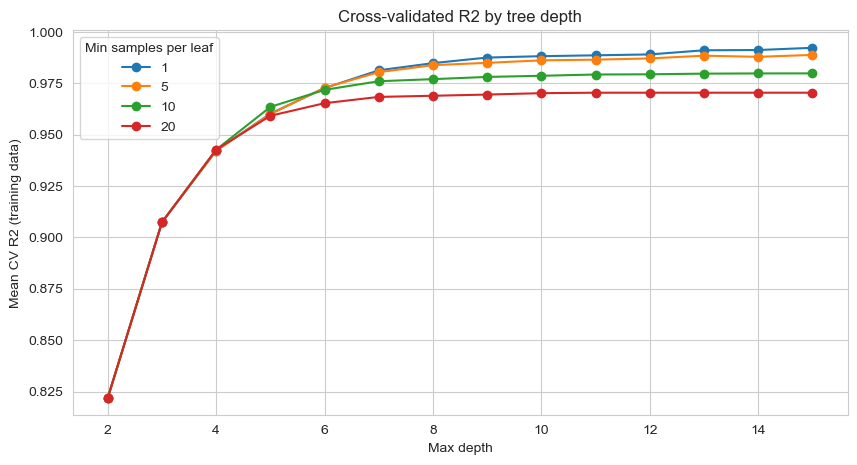

In [177]:
# Step 2 prepruning. search tree depth and minimum leaf size with 5-fold cross validation on the TRAINING data only.
param_grid = {"max_depth": list(range(2, 16)), "min_samples_leaf": [1, 5, 10, 20]}
grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                    param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train_t, y_train_t)
print("Best settings:", grid.best_params_, "| CV R2:", round(grid.best_score_, 3))

# plot the search so the choice is visible
cv_table = pd.DataFrame(grid.cv_results_)
cv_table["max_depth"] = cv_table["param_max_depth"].astype(int)
cv_table["min_samples_leaf"] = cv_table["param_min_samples_leaf"].astype(int)
pivot = cv_table.pivot(index="max_depth", columns="min_samples_leaf", values="mean_test_score")

pivot.plot(marker="o", figsize=(10, 5))
plt.title("Cross-validated R2 by tree depth")
plt.xlabel("Max depth")
plt.ylabel("Mean CV R2 (training data)")
plt.legend(title="Min samples per leaf")
save_fig("04_tree_depth_search")
plt.show()

In [178]:
# Step 3: Prefer the simplest tree whose CV score is within 0.01 of the best one
candidates = cv_table[cv_table["mean_test_score"] >= grid.best_score_ - 0.01]
simple = candidates.sort_values(["max_depth", "min_samples_leaf"],
                                ascending=[True, False]).iloc[0]

simple_tree = DecisionTreeRegressor(max_depth=int(simple["max_depth"]),
                                    min_samples_leaf=int(simple["min_samples_leaf"]),
                                    random_state=RANDOM_STATE
                                    ).fit(X_train_t, y_train_t)

final_tree, tree_label = simple_tree, "Decision tree (pruned: simplest within 0.01 CV)"
tree_scores = evaluate_model(tree_label, final_tree, X_train_t, X_test_t, y_train_t, y_test_t)
print(f"Depth {final_tree.get_depth()}, {final_tree.get_n_leaves()} leaves | "
      f"Train R2 {tree_scores['train_R2']:.3f} | Test R2 {tree_scores['test_R2']:.3f}")

# Add both tree results to the comparison list
model_results.extend([full_scores, tree_scores])

Depth 8, 108 leaves | Train R2 0.991 | Test R2 0.984


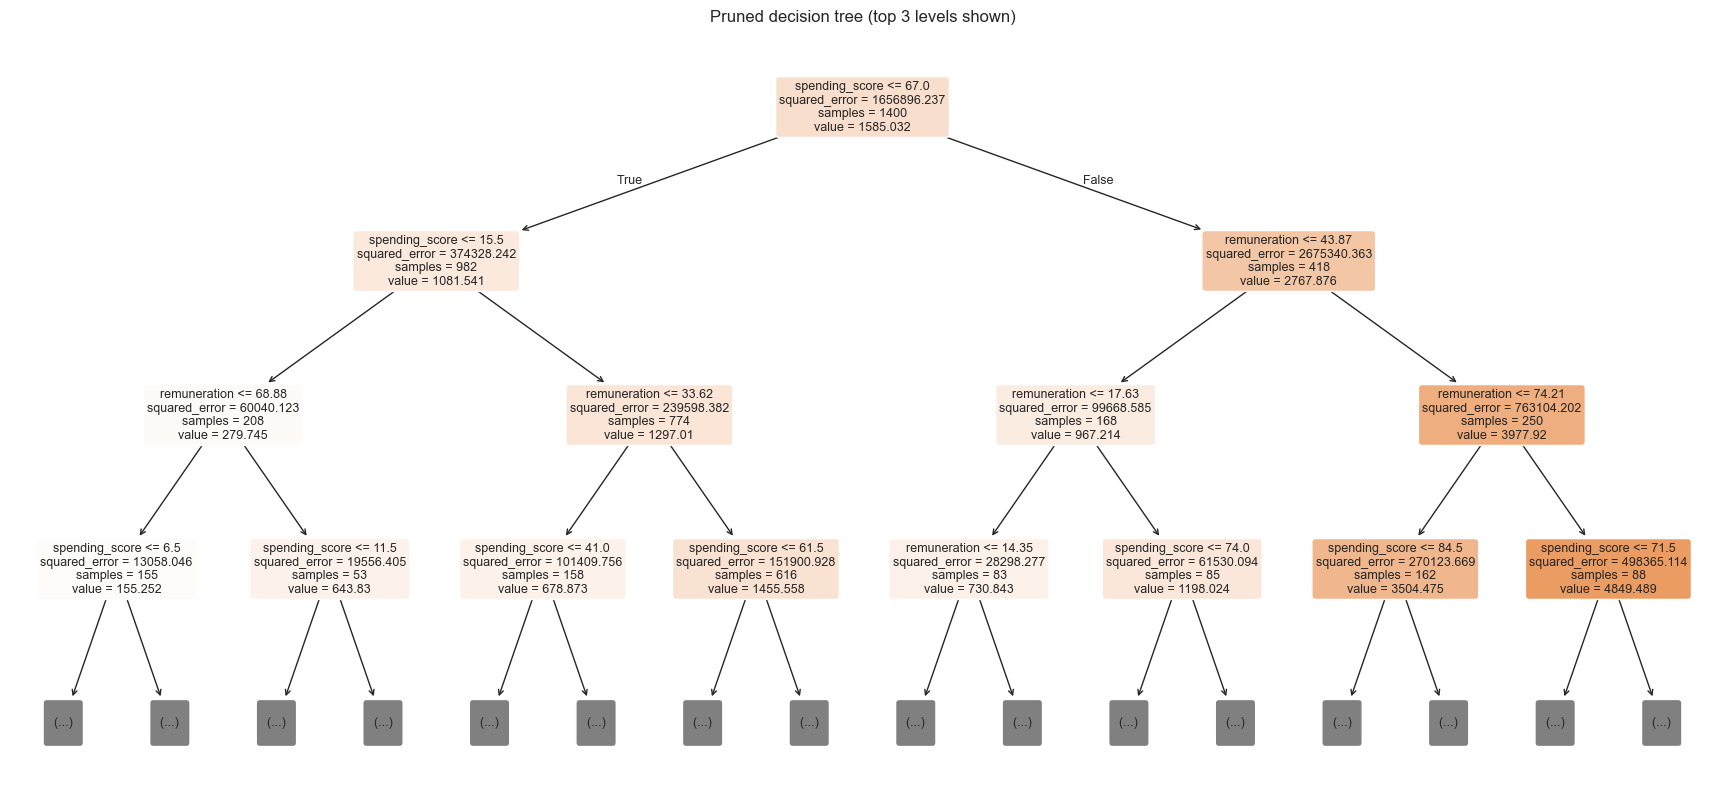

|--- spending_score <= 67.00
|   |--- spending_score <= 15.50
|   |   |--- remuneration <= 68.88
|   |   |   |--- spending_score <= 6.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- spending_score >  6.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- remuneration >  68.88
|   |   |   |--- spending_score <= 11.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- spending_score >  11.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- spending_score >  15.50
|   |   |--- remuneration <= 33.62
|   |   |   |--- spending_score <= 41.00
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- spending_score >  41.00
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- remuneration >  33.62
|   |   |   |--- spending_score <= 61.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- spending_score >  61.50
|   |   |   |   |--- value: [3020.67]
|--- spending_score >  67.00
|   |--- remuneration <= 43.8

In [179]:
# draw the top 3 levels of the tree (so the picture stays readable)
plt.figure(figsize=(22, 10))
plot_tree(final_tree, max_depth=3, feature_names=list(X_tree.columns),
          filled=True, rounded=True, fontsize=9)
plt.title("Pruned decision tree (top 3 levels shown)")
save_fig("04_decision_tree")
plt.show()

# the same top rules as plain text  
# to quote in the report
print(export_text(final_tree, feature_names=list(X_tree.columns), max_depth=3))

remuneration              0.5004
spending_score            0.4862
age                       0.0128
education_diploma         0.0003
education_postgraduate    0.0001
education_graduate        0.0001
gender_Male               0.0000
education_PhD             0.0000
dtype: float64


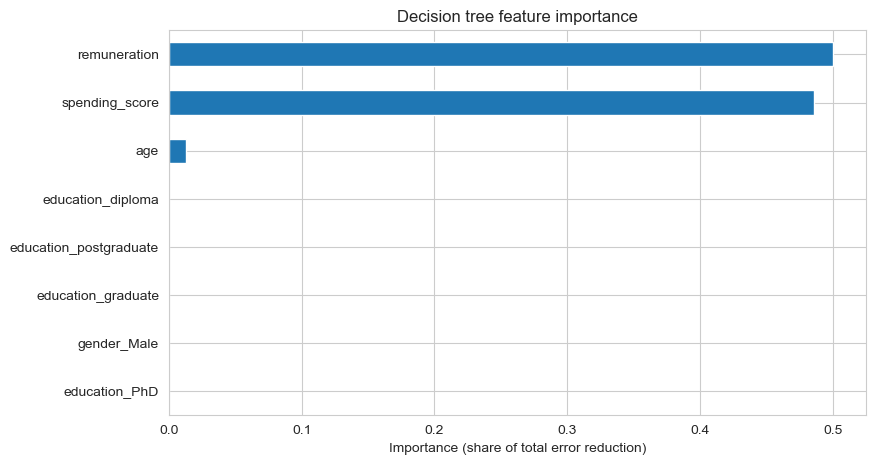

In [180]:
# which features does the tree lean on most?
tree_importance = pd.Series(final_tree.feature_importances_,
                            index=X_tree.columns).sort_values(ascending=False)
print(tree_importance.round(4))

plt.figure(figsize=(9, 5))
tree_importance.sort_values().plot.barh()
plt.title("Decision tree feature importance")
plt.xlabel("Importance (share of total error reduction)")
save_fig("04_tree_importance")
plt.show()

Random forest | Train R2 0.999 | Test R2 0.996


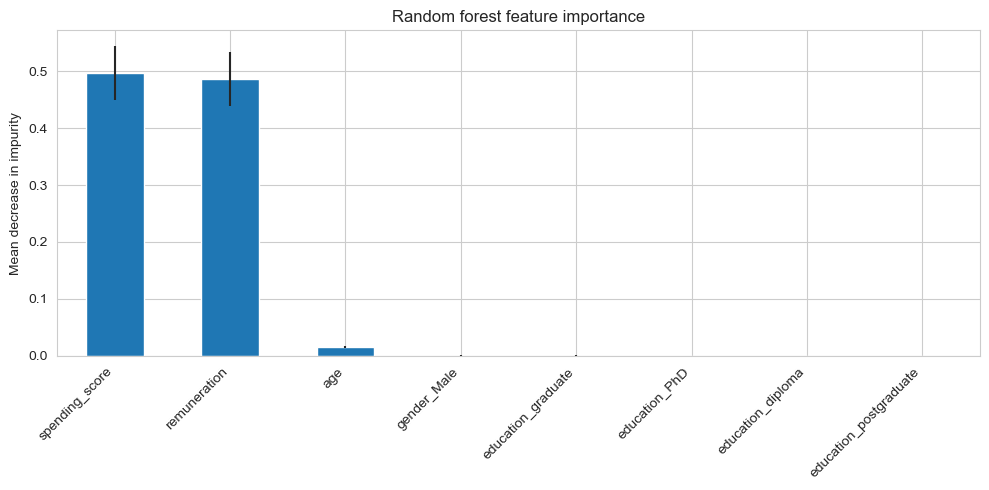

In [181]:
# Random forest: lots of trees voting together - usually more accurate and stable than one tree but harder to explain.
forest = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(X_train_t, y_train_t)

forest_scores = evaluate_model("Random forest", forest,
                               X_train_t, X_test_t, y_train_t, y_test_t)
model_results.append(forest_scores)
print(f"Random forest | Train R2 {forest_scores['train_R2']:.3f} | Test R2 {forest_scores['test_R2']:.3f}")

# Importance with error bars (spread across the individual trees)
forest_importance = pd.Series(forest.feature_importances_, index=X_tree.columns)
forest_std = pd.Series(np.std([t.feature_importances_ for t in forest.estimators_], axis=0),
                       index=X_tree.columns)
order = forest_importance.sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5))
forest_importance[order].plot.bar(yerr=forest_std[order], ax=ax)
ax.set_title("Random forest feature importance")
ax.set_ylabel("Mean decrease in impurity")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
save_fig("04_forest_importance")
plt.show()

                                                 train_R2  test_R2  test_RMSE  \
model                                                                           
Random forest                                       0.999    0.996     76.369   
Decision tree (unpruned)                            1.000    0.995     90.113   
Decision tree (pruned: simplest within 0.01 CV)     0.991    0.984    159.243   
Linear regression + interaction                     0.982    0.983    166.355   
Linear regression                                   0.844    0.830    524.670   

                                                 test_MAE  
model                                                      
Random forest                                      26.264  
Decision tree (unpruned)                           32.885  
Decision tree (pruned: simplest within 0.01 CV)    94.442  
Linear regression + interaction                   118.918  
Linear regression                                 398.027  


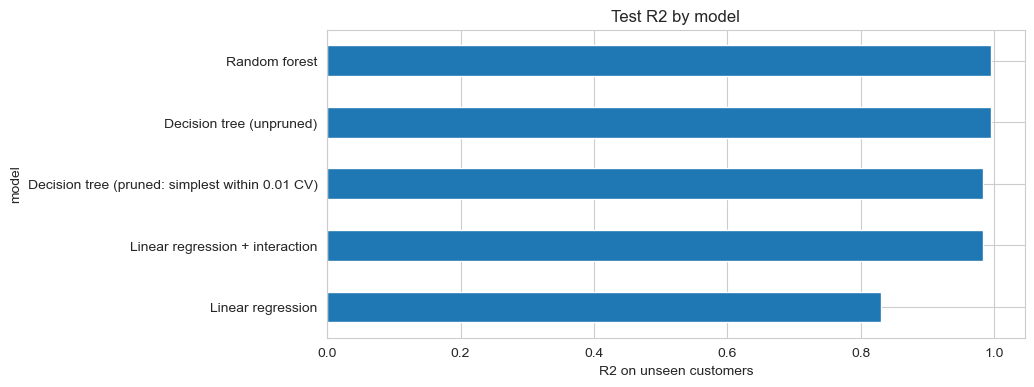


Best on unseen data: Random forest (test R2 = 0.996)


In [182]:
# remove any duplicate model results before comparison
model_results = [r for i, r in enumerate(model_results)
                 if r["model"] not in [x["model"] for x in model_results[:i]]]

comparison = (pd.DataFrame(model_results)
              .set_index("model")
              .sort_values("test_R2", ascending=False)
              .round(3))
print(comparison)

# Visual comparison of test R2
plt.figure(figsize=(9, 4))
comparison["test_R2"].sort_values().plot.barh()
plt.title("Test R2 by model")
plt.xlabel("R2 on unseen customers")
save_fig("05_model_comparison")
plt.show()

best_model_name = comparison.index[0]
print(f"\nBest on unseen data: {best_model_name} "
      f"(test R2 = {comparison.iloc[0]['test_R2']:.3f})")

In [183]:
print([r["model"] for r in model_results])

['Linear regression', 'Linear regression + interaction', 'Decision tree (unpruned)', 'Decision tree (pruned: simplest within 0.01 CV)', 'Random forest']


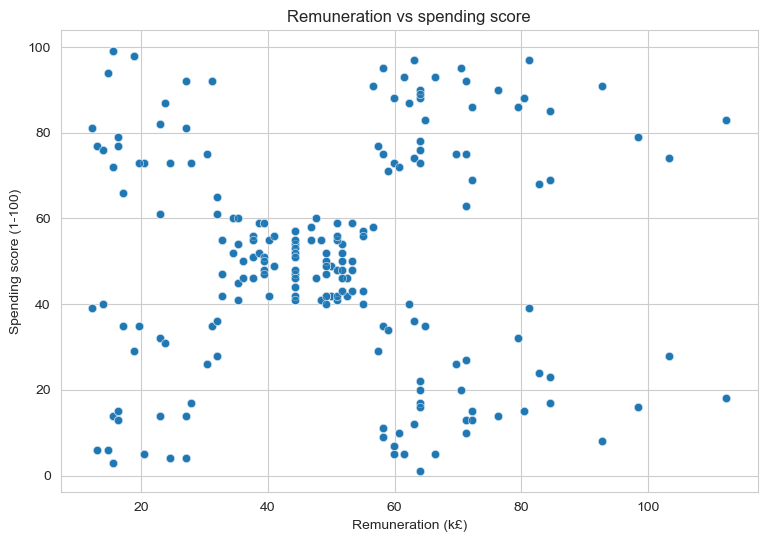

In [184]:
# two clustering variables 
X_cluster = reviews[["remuneration", "spending_score"]].to_numpy()

# Look at the raw data first: do you already see natural groups?
plt.figure(figsize=(9, 6))
sns.scatterplot(data=reviews, x="remuneration", y="spending_score", alpha=0.6)
plt.title("Remuneration vs spending score")
plt.xlabel("Remuneration (k£)")
plt.ylabel("Spending score (1-100)")
save_fig("06_cluster_raw_scatter")
plt.show()

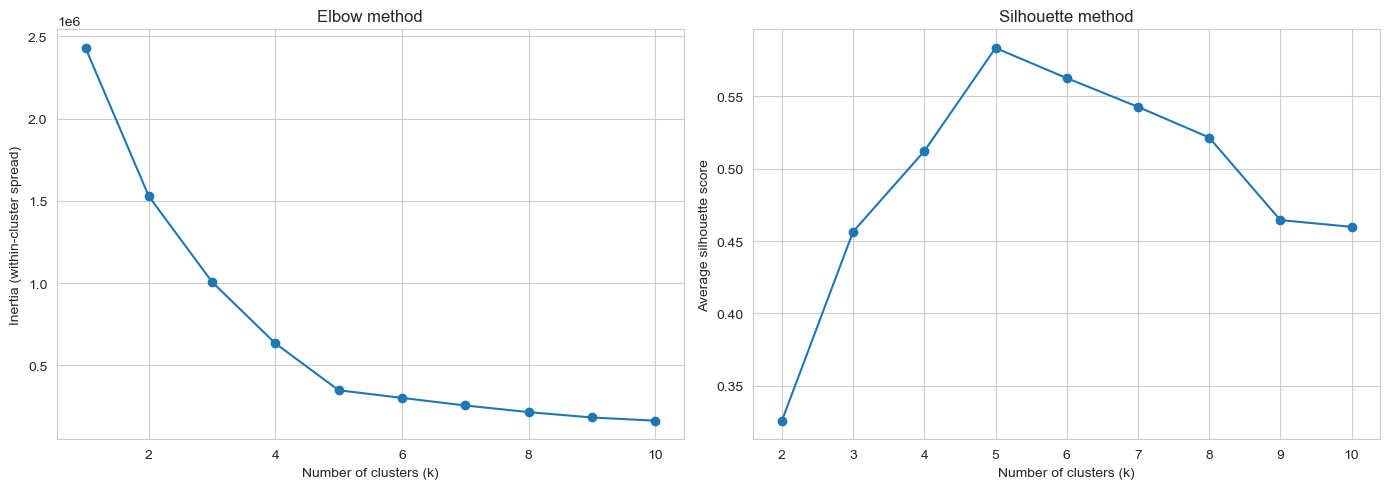

Best k by silhouette: 5 (score 0.583)


In [185]:
# Try k = 1 to 10 and record both measures
K_RANGE = range(1, 11)
inertia_values = []
silhouette_values = {}

for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X_cluster)
    inertia_values.append(km.inertia_)
    if k >= 2:   # silhouette needs at least 2 clusters
        silhouette_values[k] = silhouette_score(X_cluster, km.labels_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_RANGE), inertia_values, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster spread)")

axes[1].plot(list(silhouette_values), list(silhouette_values.values()), marker="o")
axes[1].set_title("Silhouette method")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette score")
plt.tight_layout()
save_fig("06_elbow_silhouette")
plt.show()

# Pick the k with the best silhouette score. (Check the elbow chart agrees!)
best_k = max(silhouette_values, key=silhouette_values.get)
print(f"Best k by silhouette: {best_k} (score {silhouette_values[best_k]:.3f})")

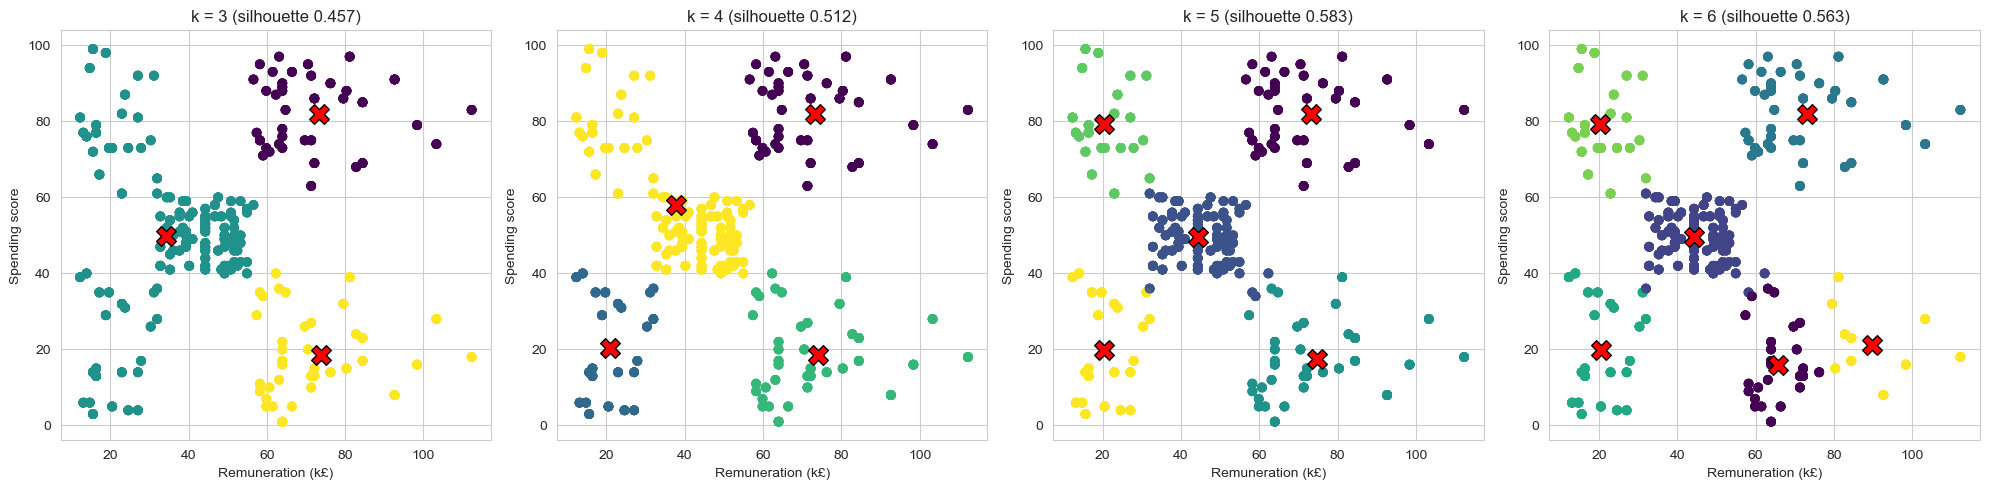

In [186]:
# Compare a few candidate k values visually before committing
candidate_ks = sorted({3, 4, best_k, min(best_k + 1, 10)})
fig, axes = plt.subplots(1, len(candidate_ks), figsize=(5 * len(candidate_ks), 5))

for ax, k in zip(np.atleast_1d(axes), candidate_ks):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_cluster)
    ax.scatter(X_cluster[:, 0], X_cluster[:, 1], c=labels, cmap="viridis", alpha=0.6)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               c="red", marker="X", s=200, edgecolors="black")
    ax.set_title(f"k = {k} (silhouette {silhouette_score(X_cluster, labels):.3f})")
    ax.set_xlabel("Remuneration (k£)")
    ax.set_ylabel("Spending score")
plt.tight_layout()
save_fig("06_candidate_clusterings")
plt.show()

In [187]:
# looks like k=5 is best 
# Fit the final model with the chosen k and attach the cluster number to each customer
kmeans_final = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
reviews["cluster"] = kmeans_final.fit_predict(X_cluster)
final_silhouette = silhouette_score(X_cluster, reviews["cluster"])
print(f"Final model: k = {best_k}, silhouette = {final_silhouette:.3f}")

# Profile each cluster - who and how many
profile = reviews.groupby("cluster").agg(
    customers=("cluster", "size"),
    avg_remuneration=("remuneration", "mean"),
    avg_spending_score=("spending_score", "mean"),
    avg_age=("age", "mean"),
    avg_loyalty_points=("loyalty_points", "mean"),
).round(1)
profile["pct_of_customers"] = (100 * profile["customers"] / len(reviews)).round(1)


def level(value, reference):
    """Label a value Low / Mid / High versus the bottom, middle and top third of customers."""
    low, high = reference.quantile([1 / 3, 2 / 3])
    if value <= low:
        return "Low"
    if value >= high:
        return "High"
    return "Mid"


# Give each cluster a sesnible name based on its average income and spending
segment_names = {}
for cluster_id, row in profile.iterrows():
    income = level(row["avg_remuneration"], reviews["remuneration"])
    spend = level(row["avg_spending_score"], reviews["spending_score"])
    segment_names[cluster_id] = f"C{cluster_id}: {income} income / {spend} spend"

reviews["segment"] = reviews["cluster"].map(segment_names)
profile["segment"] = pd.Series(segment_names)
print()
print(profile)

Final model: k = 5, silhouette = 0.583

         customers  avg_remuneration  avg_spending_score  avg_age  \
cluster                                                             
0              356              73.2                82.0     35.6   
1              774              44.4                49.5     42.1   
2              330              74.8                17.4     40.7   
3              269              20.4                79.4     31.6   
4              271              20.4                19.8     43.5   

         avg_loyalty_points  pct_of_customers                       segment  
cluster                                                                      
0                    3988.2              17.8  C0: High income / High spend  
1                    1420.4              38.7    C1: Mid income / Mid spend  
2                     911.8              16.5   C2: High income / Low spend  
3                     971.9              13.4   C3: Low income / High spend  
4       

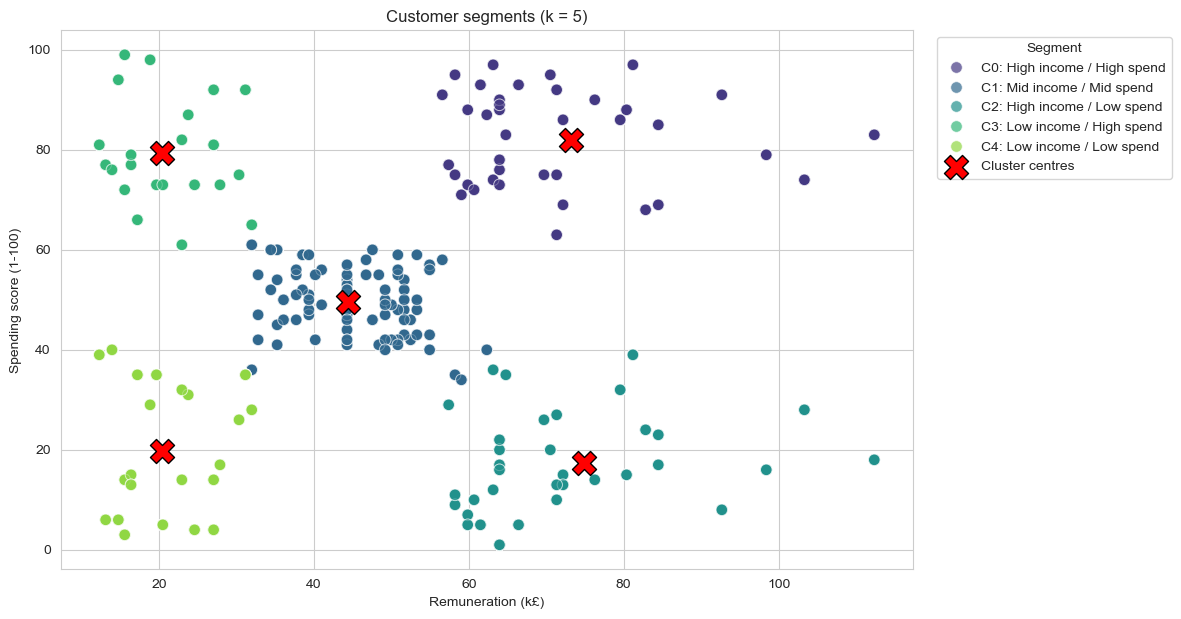

In [188]:
# Final cluster chart, with sensible names in the legend
plt.figure(figsize=(11, 7))
sns.scatterplot(data=reviews.sort_values("cluster"), x="remuneration", y="spending_score",
                hue="segment", palette="viridis", s=70, alpha=0.7)
plt.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
            c="red", marker="X", s=300, edgecolors="black", label="Cluster centres")
plt.title(f"Customer segments (k = {best_k})")
plt.xlabel("Remuneration (k£)")
plt.ylabel("Spending score (1-100)")
plt.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
save_fig("06_final_segments")
plt.show()

In [189]:
#  two text columns (keeping the same row numbers so we can join back later)
text_df = reviews[["review", "summary"]].copy()

# missing text becomes an empty string
print("Missing before:", text_df.isna().sum().to_dict())
text_df = text_df.fillna("").astype(str)


def clean_text(text):
    """Lower-case, keep only letters and apostrophes, collapse extra spaces."""
    text = text.lower()
    text = re.sub(r"[^a-z\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()


text_df["review_clean"] = text_df["review"].apply(clean_text)
text_df["summary_clean"] = text_df["summary"].apply(clean_text)

# compare before and after on a few rows
text_df[["review", "review_clean"]].head(5)

Missing before: {'review': 0, 'summary': 0}


,review,review_clean
0,"When it comes to a DM's screen, the space on t...",when it comes to a dm's screen the space on th...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,an open letter to galeforce your unpainted min...
2,"Nice art, nice printing. Why two panels are f...",nice art nice printing why two panels are fill...
3,Amazing buy! Bought it as a gift for our new d...,amazing buy bought it as a gift for our new dm...
4,As my review of GF9's previous screens these w...,as my review of gf 's previous screens these w...


In [190]:
# Top 15 words in reviews after removing stopwords
top_reviews = top_words_without_stopwords(reviews["review_clean"])

print("Top 15 words in reviews:")
print(top_reviews)


# Top 15 words in summaries after removing stopwords
top_summaries = top_words_without_stopwords(reviews["summary_clean"])

print("\nTop 15 words in summaries:")
print(top_summaries)

Top 15 words in reviews:
      word  count
0     game   1685
1    great    596
2      fun    553
3      one    530
4     play    502
5     like    414
6     love    331
7   really    319
8      get    319
9    cards    301
10   tiles    297
11    good    294
12    time    291
13   would    280
14    book    273

Top 15 words in summaries:
         word  count
0       stars    466
1        five    381
2        game    319
3       great    295
4         fun    218
5        love     93
6        good     92
7        four     58
8        like     54
9   expansion     52
10       kids     50
11       cute     45
12       book     43
13        one     38
14    awesome     36


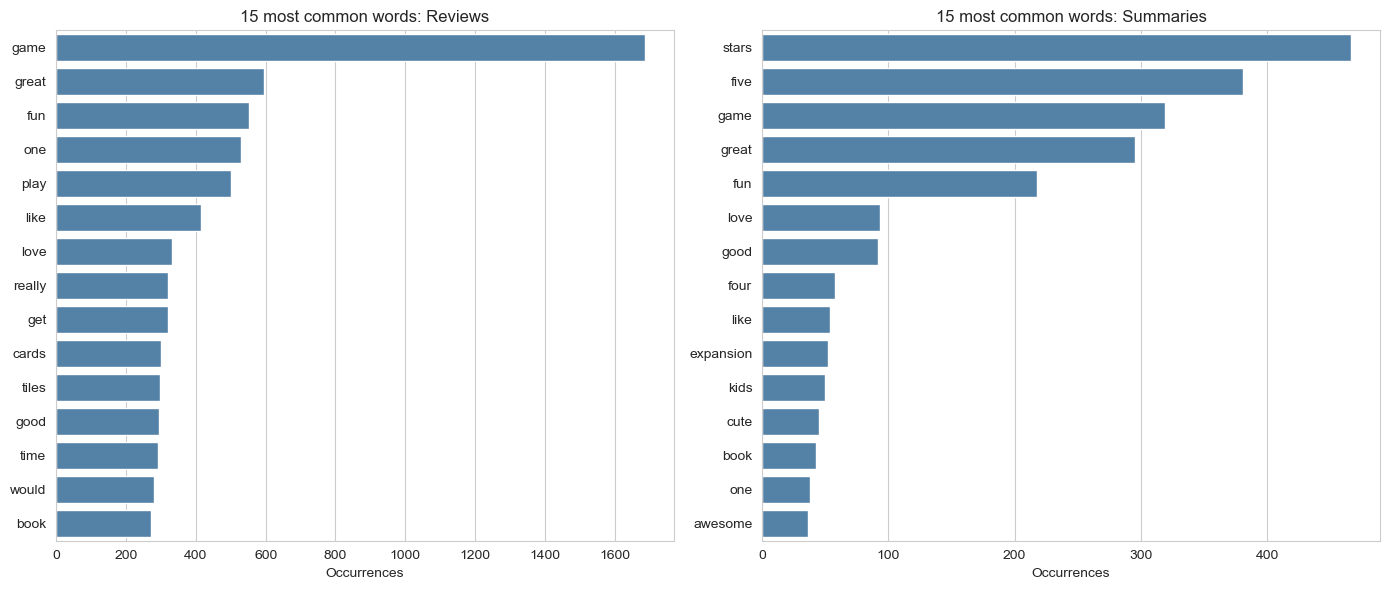

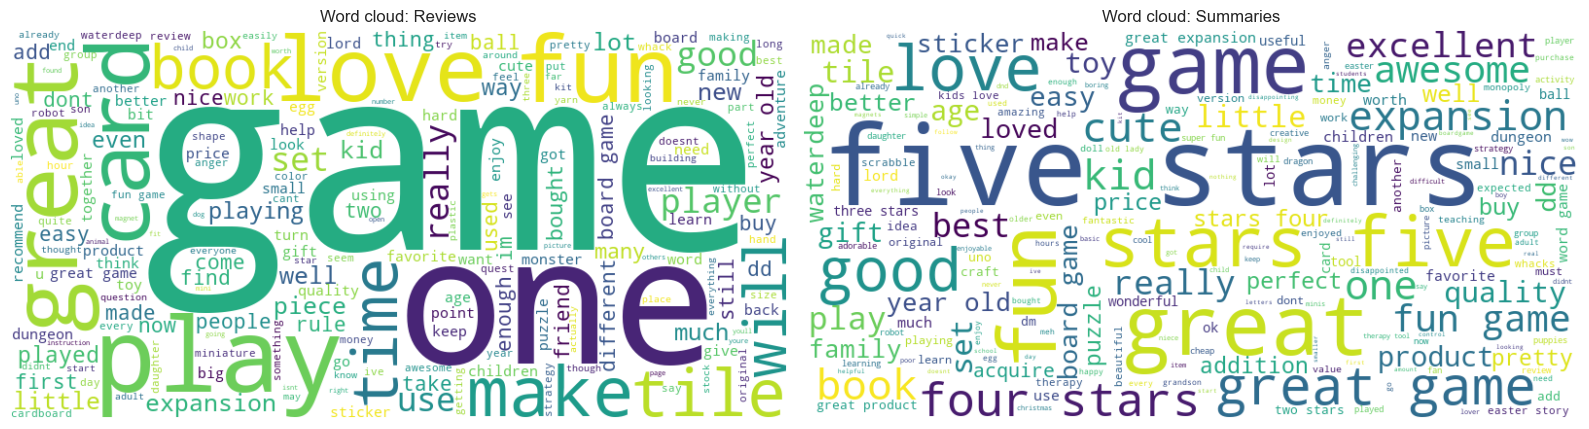

In [191]:
# bar charts of the top 15 words in each column
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, data, title in zip(
    axes,
    [top_reviews, top_summaries],
    ["Reviews", "Summaries"]
):
    sns.barplot(data=data, x="count", y="word", color="steelblue", ax=ax)
    ax.set_title(f"15 most common words: {title}")
    ax.set_xlabel("Occurrences")
    ax.set_ylabel("")

plt.tight_layout()
save_fig("07_top15_words")
plt.show()


# Word clouds
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, text, title in zip(
    axes,
    [reviews["review_clean"], reviews["summary_clean"]],
    ["Reviews", "Summaries"]
):
    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(" ".join(text.dropna()))

    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"Word cloud: {title}")
    ax.axis("off")

plt.tight_layout()
save_fig("07_word_clouds")
plt.show()

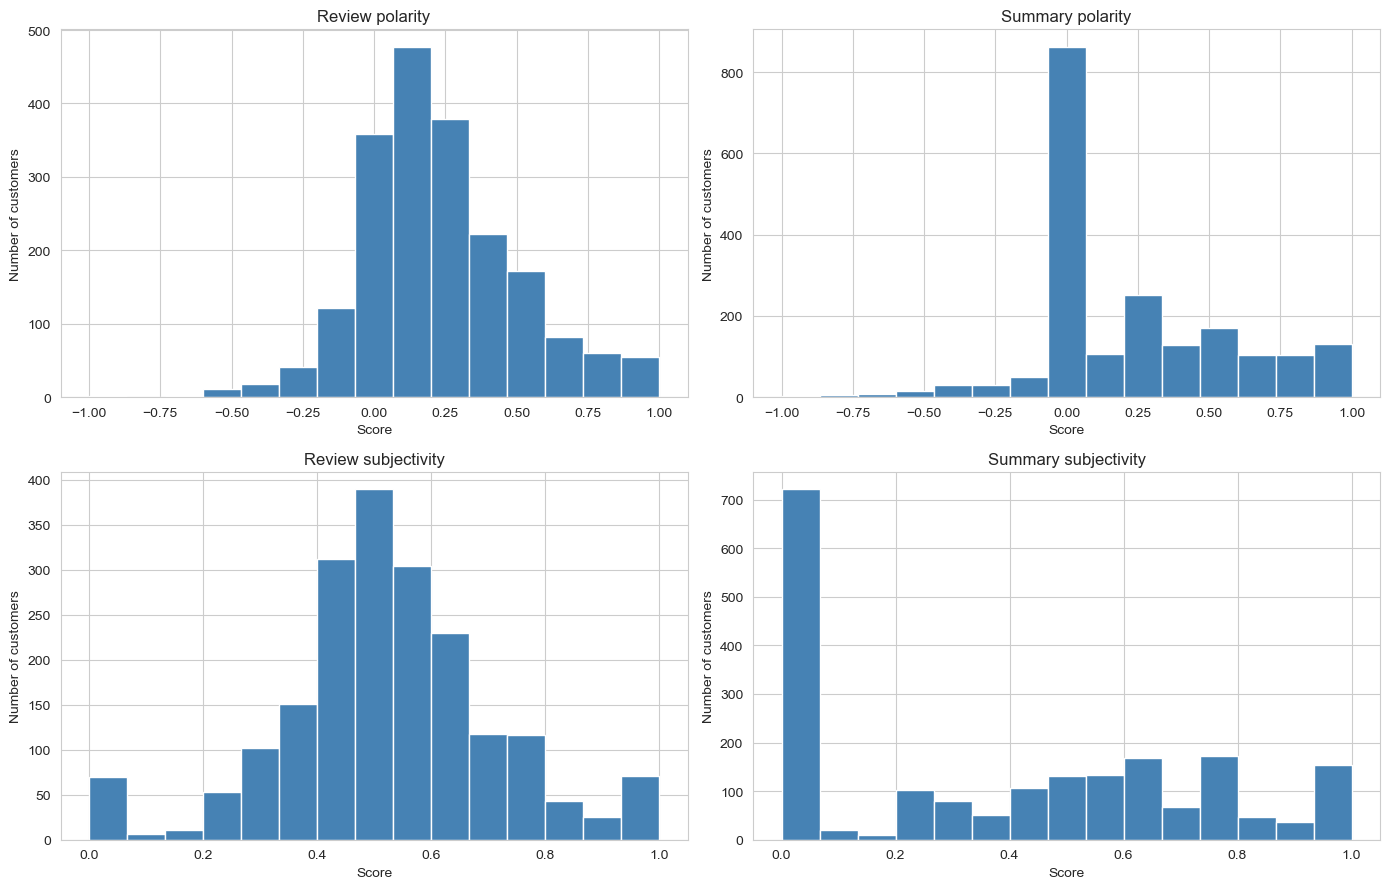

       review_polarity  summary_polarity  review_subjectivity  \
count         2000.000          2000.000             2000.000   
mean             0.226             0.229                0.520   
std              0.275             0.352                0.193   
min             -1.000            -1.000                0.000   
25%              0.049             0.000                0.425   
50%              0.183             0.064                0.512   
75%              0.375             0.488                0.607   
max              1.000             1.000                1.000   

       summary_subjectivity  
count              2000.000  
mean                  0.378  
std                   0.342  
min                   0.000  
25%                   0.000  
50%                   0.400  
75%                   0.633  
max                   1.000  


In [192]:
# Sentiment scores for every review and summary
# TextBlob can handle punctuation, so score the original text
def polarity(text):
    return TextBlob(str(text)).sentiment.polarity

def subjectivity(text):
    return TextBlob(str(text)).sentiment.subjectivity


reviews["review_polarity"] = reviews["review"].apply(polarity)
reviews["review_subjectivity"] = reviews["review"].apply(subjectivity)

reviews["summary_polarity"] = reviews["summary"].apply(polarity)
reviews["summary_subjectivity"] = reviews["summary"].apply(subjectivity)


# Histograms (15 bins as the brief asks)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plots = [
    ("review_polarity", "Review polarity"),
    ("summary_polarity", "Summary polarity"),
    ("review_subjectivity", "Review subjectivity"),
    ("summary_subjectivity", "Summary subjectivity")
]

for ax, (col, title) in zip(axes.ravel(), plots):
    ax.hist(reviews[col], bins=15, color="steelblue", edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of customers")

plt.tight_layout()
save_fig("07_sentiment_histograms")
plt.show()


print(
    reviews[
        ["review_polarity", "summary_polarity",
         "review_subjectivity", "summary_subjectivity"]
    ].describe().round(3)
)

Share of reviews by sentiment (%):
review_sentiment
Positive    65.8
Neutral     27.0
Negative     7.2
Name: proportion, dtype: float64

Reviews with polarity >= 0.8 (very positive): 4.5%


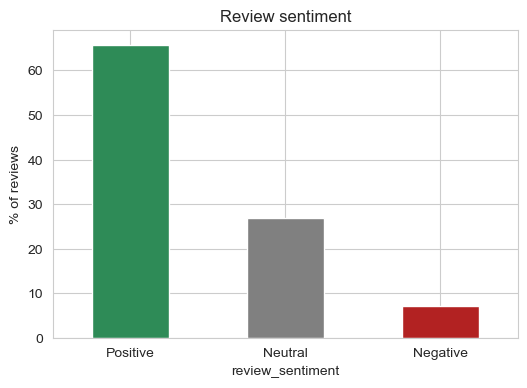

In [193]:
# Turn the scores into labels
# scores above 0.1 are positive, below -0.1 are negative, and values in between are neutral.
def sentiment_label(score):
    if score > 0.1:
        return "Positive"
    if score < -0.1:
        return "Negative"
    return "Neutral"


reviews["review_sentiment"] = reviews["review_polarity"].apply(sentiment_label)

share = reviews["review_sentiment"].value_counts(normalize=True).mul(100).round(1)

print("Share of reviews by sentiment (%):")
print(share)

print(
    f"\nReviews with polarity >= 0.8 (very positive): "
    f"{(reviews['review_polarity'] >= 0.8).mean():.1%}"
)


plt.figure(figsize=(6, 4))

share.reindex(["Positive", "Neutral", "Negative"]).plot.bar(
    color=["seagreen", "grey", "firebrick"]
)

plt.title("Review sentiment")
plt.ylabel("% of reviews")
plt.xticks(rotation=0)

save_fig("07_sentiment_share")
plt.show()

In [194]:
# Top 20 most positive and most negative reviews and summaries
# where scores tie, pandas keeps original file order
def show_extremes(column, score_column, n=20):
    top = reviews.nlargest(n, score_column)[[column, score_column]]
    bottom = reviews.nsmallest(n, score_column)[[column, score_column]]

    print(f"\n== TOP {n} POSITIVE ({column}) ==")
    print(top.to_string(max_colwidth=90))

    print(f"\n== TOP {n} NEGATIVE ({column}) ==")
    print(bottom.to_string(max_colwidth=90))


show_extremes("review", "review_polarity")
show_extremes("summary", "summary_polarity")


== TOP 20 POSITIVE (review) ==
                                                                                        review  review_polarity
7                                                                   Came in perfect condition.              1.0
44                                             Absolutely great pictures even before coloring!              1.0
55                                                                                      Great!              1.0
165                                                                               Awesome book              1.0
194                                                                               Awesome gift              1.0
216                                                           Great product!  Arrived on time.              1.0
318                                                   Great buy!!  My granddaughter loves it!!              1.0
371                                                                     

In [195]:
# Sanity check on the dictionary scorer.
# Surprising scores are a reminder of TextBlob's limitations.
word_check = top_reviews.copy()
word_check["polarity"] = word_check["word"].apply(polarity)
print(word_check)

      word  count  polarity
0     game   1685      -0.4
1    great    596       0.8
2      fun    553       0.3
3      one    530       0.0
4     play    502       0.0
5     like    414       0.0
6     love    331       0.5
7   really    319       0.2
8      get    319       0.0
9    cards    301       0.0
10   tiles    297       0.0
11    good    294       0.7
12    time    291       0.0
13   would    280       0.0
14    book    273       0.0


In [196]:
# Extra insight:
# see whether happier reviewers differ across customer segments and if sentiment is related to key customer metrics

print("Average review sentiment by customer segment:")
print(
    reviews.groupby("segment")["review_polarity"]
    .mean()
    .round(3)
    .sort_values(ascending=False)
)

print("\nCorrelation of review sentiment with customer metrics:")
print(
    reviews[
        ["review_polarity", "spending_score", "remuneration",
         "age", "loyalty_points"]
    ]
    .corr()["review_polarity"]
    .drop("review_polarity")
    .round(3)
)

Average review sentiment by customer segment:
segment
C0: High income / High spend    0.244
C2: High income / Low spend     0.238
C3: Low income / High spend     0.233
C1: Mid income / Mid spend      0.214
C4: Low income / Low spend      0.213
Name: review_polarity, dtype: float64

Correlation of review sentiment with customer metrics:
spending_score    0.022
remuneration      0.019
age              -0.040
loyalty_points    0.016
Name: review_polarity, dtype: float64


In [197]:
# Everything we learned about each customer in one file
reviews.to_csv("turtle_reviews_python_results.csv", index=False)
comparison.to_csv("model_comparison.csv", index=False)
profile.to_csv("segment_profile.csv", index=False)

print("Saved: turtle_reviews_python_results.csv, model_comparison.csv, segment_profile.csv")


# Headline numbers
# Pulled directly from the results above so they cannot go out of sync
print("\n== HEADLINE NUMBERS ==")
print(f"Customers analysed: {len(reviews)}")
print(
    f"Loyalty points: skewness {skew_lp:.2f}, "
    f"excess kurtosis {kurt_lp:.2f} -> {describe_skew(skew_lp)}"
)
print(f"Linear regression test R2: {linear_scores['test_R2']:.3f}")
print(
    f"Best model: {best_model_name} "
    f"(test R2 {comparison.iloc[0]['test_R2']:.3f})"
)
print(f"Top tree drivers: {', '.join(tree_importance.head(3).index)}")
print(f"Customer segments: {best_k} (silhouette {final_silhouette:.3f})")
print(
    f"Positive reviews: {share.get('Positive', 0):.1f}% | "
    f"Negative: {share.get('Negative', 0):.1f}%"
)
print(f"Top 3 review words: {', '.join(top_reviews['word'].head(3))}")

Saved: turtle_reviews_python_results.csv, model_comparison.csv, segment_profile.csv

== HEADLINE NUMBERS ==
Customers analysed: 2000
Loyalty points: skewness 1.46, excess kurtosis 1.71 -> strongly skewed to the right (long tail of high values)
Linear regression test R2: 0.830
Best model: Random forest (test R2 0.996)
Top tree drivers: remuneration, spending_score, age
Customer segments: 5 (silhouette 0.583)
Positive reviews: 65.8% | Negative: 7.2%
Top 3 review words: game, great, fun
